# Marketing Growth Analytics

# Penjelasan Dataset

| Column Name | Data Type | Description |
| :--- | :--- | :--- |
| **user_id** | `int64` | Nomor atau identifikasi unik untuk setiap pengguna (*user*) yang tercatat dalam sistem. |
| **first_visit_date** | `object` | Tanggal pertama kali pengguna mengunjungi situs web atau platform. |
| **channel** | `object` | Saluran pemasaran utama tempat pengguna berasal (misalnya: *Referral*, *Paid Ads*, *Organic Search*, *Social Media*, *Email*). |
| **source** | `object` | Sumber spesifik dari lalu lintas kunjungan atau platform spesifik (misalnya: *instagram*, *facebook*, *tiktok*, *direct*, *google*). |
| **device** | `object` | Jenis perangkat yang digunakan oleh pengguna saat mengakses platform (misalnya: *Mobile*, *Desktop*, *Tablet*). |
| **sessions** | `int64` | Jumlah total sesi kunjungan yang dilakukan oleh pengguna ke situs. |
| **page_views** | `int64` | Total halaman yang dilihat atau dikunjungi oleh pengguna selama sesi mereka di platform. |
| **bounce** | `int64` | Status *bounce* (1 jika pengguna meninggalkan situs tanpa interaksi lanjutan, 0 jika tidak). |
| **add_to_cart** | `int64` | Indikator apakah pengguna pernah menambahkan produk ke keranjang belanja (1 untuk Ya, 0 untuk Tidak). |
| **purchase** | `int64` | Indikator apakah pengguna berhasil melakukan transaksi pembelian (1 untuk Ya, 0 untuk Tidak). |
| **revenue** | `int64` | Total pendapatan moneter yang dihasilkan dari pembelian yang dilakukan oleh pengguna. |
| **ad_cost** | `int64` | Biaya iklan yang dikeluarkan oleh tim pemasaran untuk mengakuisisi atau menargetkan pengguna. |
| **clicks** | `int64` | Jumlah klik yang terjadi pada iklan atau tautan pemasaran terkait pengguna. |
| **impressions** | `int64` | Jumlah tayangan (*impressions*) iklan yang dilihat oleh pengguna. |
| **repeat_purchase** | `int64` | Indikator apakah pengguna melakukan pembelian ulang setelah transaksi pertama (1 untuk Ya, 0 untuk Tidak). |
| **retention_month** | `int64` | Angka yang menunjukkan bulan retensi atau berapa bulan pengguna tersebut tetap aktif sejak kunjungan pertamanya. |

# Import Data

# Library yang Digunakan

In [11]:
import pandas as pd # Digunakan untuk mengimpor, mengelola, membersihkan, dan menganalisis data dalam format tabel dua dimensi (tabular data).
import numpy as np # Digunakan untuk komputasi numerik berskala besar, termasuk membantu perhitungan fungsi massa probabilitas (Probability Mass Function / PMF) serta operasi matematika dan analisis statistik.
import matplotlib.pyplot as plt # Digunakan sebagai pustaka dasar untuk merancang dan membuat visualisasi data dua dimensi, seperti grafik garis, diagram batang, dan tebaran titik.
import seaborn as sns # Digunakan untuk membuat visualisasi data bertema statistik yang lebih estetis, modern, dan informatif dengan sintaks yang lebih ringkas.
from scipy import stats # Digunakan untuk melakukan berbagai komputasi, pengujian, dan analisis statistik tingkat lanjut, seperti uji hipotesis, perhitungan nilai probabilitas (p-value), serta pengelolaan berbagai jenis distribusi statistik.

# Load Dataset

In [12]:
df=pd.read_csv(r"C:\Users\HP\Downloads\practical_data_marketing_growth_analytics.csv") # Data disimpan di folder 'Downloads' dengan nama 'Cafe_Sales.csv'

# Data Exploration

## Menampilkan Data

df.head() menampilkan beberapa baris teratas atau pertama dari dataset

In [13]:
df.head()

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0


df.info() memberikan ringkasan struktur DataFrame, termasuk jumlah baris, kolom, tipe data, nilai non-null, dan penggunaan memori, membantu memahami data sebelum analisis.

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           800 non-null    int64
 1   first_visit_date  800 non-null    str  
 2   channel           800 non-null    str  
 3   source            800 non-null    str  
 4   device            800 non-null    str  
 5   sessions          800 non-null    int64
 6   page_views        800 non-null    int64
 7   bounce            800 non-null    int64
 8   add_to_cart       800 non-null    int64
 9   purchase          800 non-null    int64
 10  revenue           800 non-null    int64
 11  ad_cost           800 non-null    int64
 12  clicks            800 non-null    int64
 13  impressions       800 non-null    int64
 14  repeat_purchase   800 non-null    int64
 15  retention_month   800 non-null    int64
dtypes: int64(12), str(4)
memory usage: 125.8 KB


kolom first_visit_date perlu diubah menjadi datetime

# Menampilkan ringkasan statistik

In [15]:
df.describe()

,user_id,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,4.131250,10.053750,0.032500,0.411250,0.187500,51254.881250,13686.133750,24.366250,553.375000,0.060000,0.427500
std,231.0844,1.970121,5.482329,0.177435,0.492368,0.390557,121909.726919,23499.467179,14.369071,427.273115,0.237635,1.100572
min,1.0000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,8.000000,0.000000,0.000000
25%,200.7500,3.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,11.000000,208.750000,0.000000,0.000000
50%,400.5000,4.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.000000,442.000000,0.000000,0.000000
75%,600.2500,6.000000,15.000000,0.000000,1.000000,0.000000,0.000000,21996.750000,37.000000,812.000000,0.000000,0.000000
max,800.0000,7.000000,19.000000,1.000000,1.000000,1.000000,495675.000000,79437.000000,49.000000,1911.000000,1.000000,5.000000


Dari hasil ringkasan statistik pada data ini:
- Ukuran Dataset (count): Terdiri dari 800 baris data tanpa ada nilai yang kosong (missing values) pada seluruh kolom numerik.
- Aktivitas Pengguna (sessions & page_views): Rata-rata pengguna melakukan 4,13 sesi kunjungan dengan sekitar 10 halaman yang dilihat per kunjungan.
- Tambah ke Keranjang (add_to_cart): Hanya 41,12% pengguna yang memasukkan produk ke keranjang.
- Rasio Pembelian (purchase): Sekitar 18,75% dari total pengguna berhasil melakukan transaksi pembelian.
- Retensi & Loyalitas (repeat_purchase & retention_month): Hanya 6% pengguna yang melakukan pembelian ulang (repeat purchase), dengan rata-rata keaktifan selama 0,42 bulan.
- Kesimpulan: Ada potensi masalah atau hambatan (bottleneck) di halaman checkout atau cart, karena lebih dari separuh orang yang sudah memasukkan barang ke keranjang akhirnya batal membeli. Selain itu, retensi untuk pembelian kedua masih sangat rendah.
- Pendapatan & Biaya Iklan (revenue & ad_cost): Mayoritas pengguna (lebih dari 75%) bernilai 0 karena tidak menghasilkan pendapatan atau tidak menggunakan biaya iklan, dengan pendapatan maksimum mencapai 495.675.
- Tayangan vs Klik: Rata-rata impressions iklan adalah 553,37 dengan clicks rata-rata 24,36. Jika dihitung secara kasar, rasio klik (Click-Through Rate / CTR) berada di kisaran 4,4%, yang merupakan angka yang cukup wajar dalam dunia periklanan digital.
- Biaya Maksimum: Biaya iklan tertinggi mencapai 79.437, sementara pendapatan maksimum mencapai 495.675, yang menunjukkan bahwa kampanye pemasaran tertentu memberikan Return on Ad Spend / ROAS yang sangat tinggi.
- Saluran Paid Ads adalah yang terbanyak digunakan dalam dataset ini dengan total 251 pengguna, disusul oleh Organic Search (198 pengguna) dan Social Media (151 pengguna).
- Pengguna mayoritas mengakses melalui Mobile sebanyak 504 orang (lebih dari 60%), disusul oleh Desktop (262 orang), dan Tablet (34 orang). Ini mengonfirmasi bahwa strategi mobile-first sangat krusial untuk dataset ini.
- Pada kolom revenue dan ad_cost, nilai persentil ke-25, 50 (median), hingga ke-75 semuanya bernilai 0. Artinya, lebih dari 75% baris data tidak memiliki pengeluaran iklan atau tidak menghasilkan pendapatan. Hanya sebagian kecil pengguna (power users atau kelompok tertarget tertentu) yang benar-benar menghasilkan revenue atau menggunakan anggaran iklan (ad_cost).

# Distribusi Data

- Dilakukan pemeriksaan distribusi data untuk mengetahui pola sebaran nilai pada setiap variabel.
- Pemeriksaan ini bertujuan untuk melihat apakah data berdistribusi normal atau tidak, sehingga dapat ditentukan metode analisis yang sesuai pada tahap selanjutnya.
- Pemriksaan persebaran data menggunakan Uji Normalitas Shapiro-Wilk.

## Uji Normalitas Statistik

In [16]:
# Memilih hanya kolom yang bertipe numerik
numeric_cols = df.select_dtypes(include=['number']).columns

# Melakukan uji Shapiro-Wilk untuk setiap kolom numerik
for col in numeric_cols:
    stat, p_value = stats.shapiro(df[col].dropna())
    print(f"Kolom: {col}")
    print(f"  - Statistik: {stat:.4f}")
    print(f"  - P-value: {p_value:.4f}")
    
    if p_value > 0.05:
        print(f"  - Hasil: Berdistribusi Normal (Terima H0)\n")
    else:
        print(f"  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)\n")

Kolom: user_id
  - Statistik: 0.9548
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: sessions
  - Statistik: 0.9215
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: page_views
  - Statistik: 0.9484
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: bounce
  - Statistik: 0.1680
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: add_to_cart
  - Statistik: 0.6250
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: purchase
  - Statistik: 0.4754
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: revenue
  - Statistik: 0.4787
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: ad_cost
  - Statistik: 0.6326
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: clicks
  - Statistik: 0.9461
  - P-value: 0.0000
  - Hasil: TIDAK Berdistribusi Normal (Tolak H0)

Kolom: impressions
  - Statist

Distribusi data yang tidak normal pada data marketing growth adalah hal yang sangat wajar dan justru merupakan karakteristik bawaan dari metrik pertumbuhan bisnis.

## Visualisasi Distribusi Data Numerikal

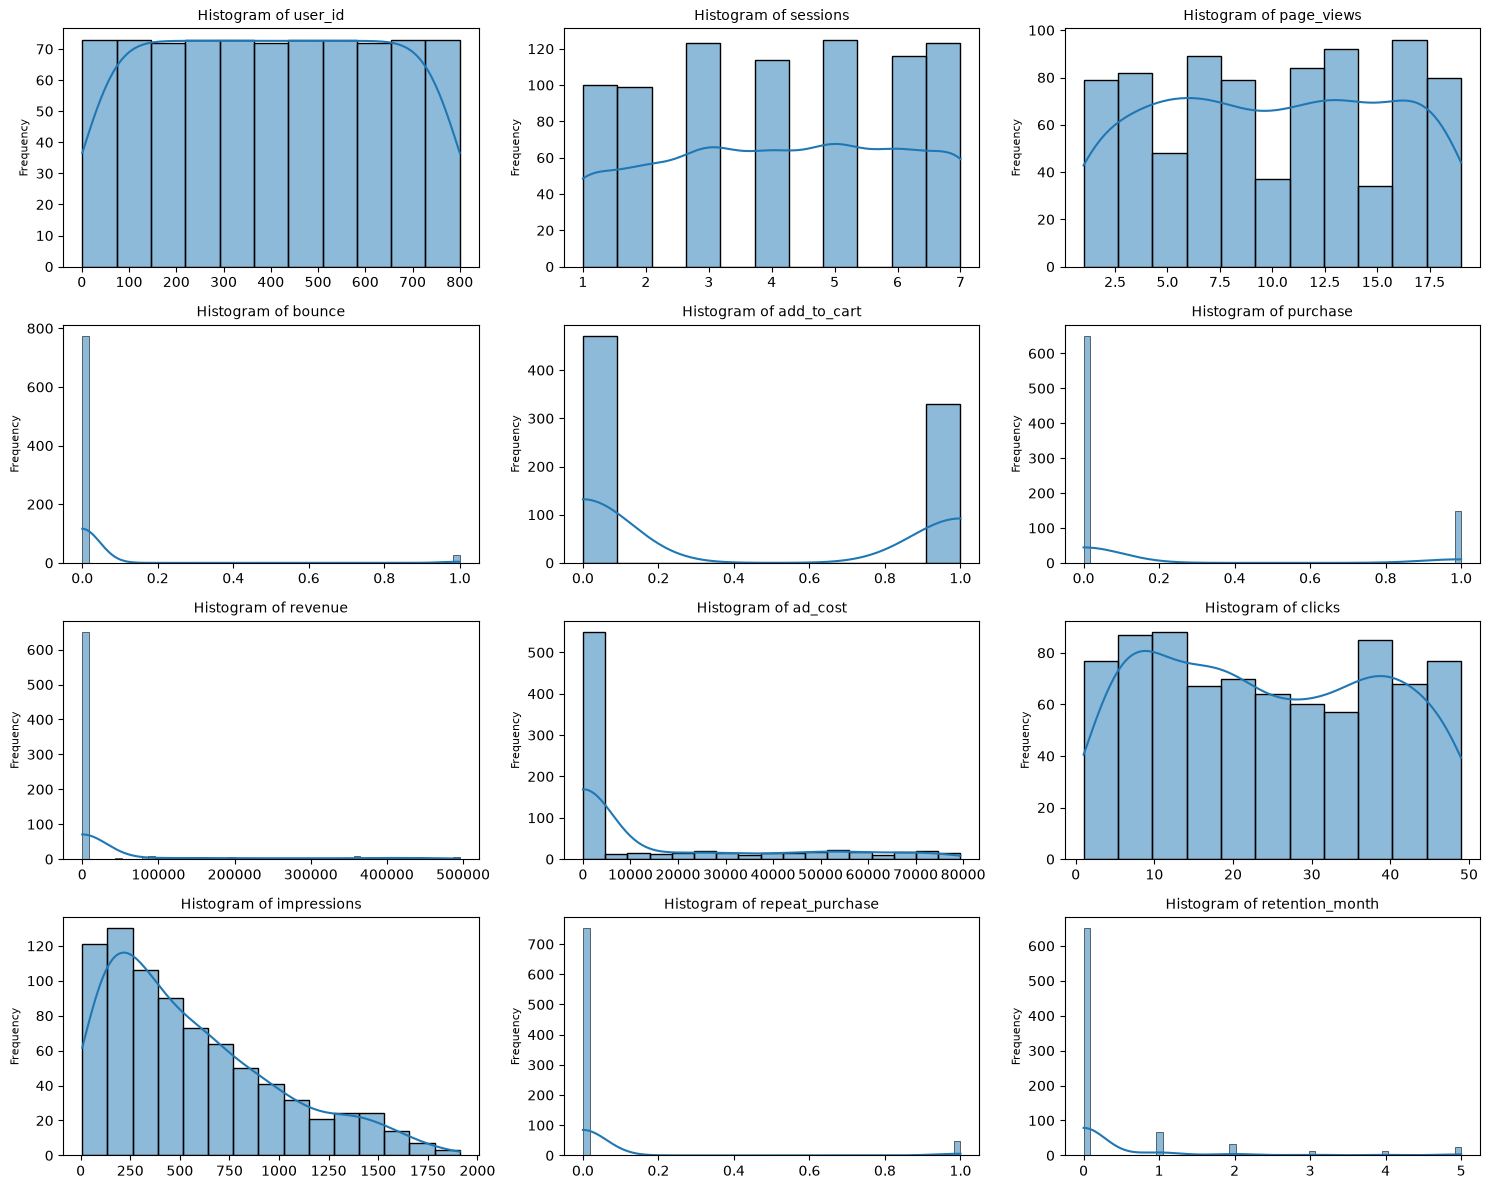

In [17]:
# Memilih hanya kolom numerik
numeric_cols = df.select_dtypes(include=['number']).columns

# Membuat layout grid subplots (4 baris x 3 kolom)
fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 12))
axes = axes.flatten()

# Looping untuk menggambar histogram pada setiap subplot
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Histogram of {col}', fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frequency', fontsize=8)

# Merapikan tata letak agar tidak tumpang tindih
plt.tight_layout()
plt.show()

## Visualisasi Distribusi Data Kategorikal

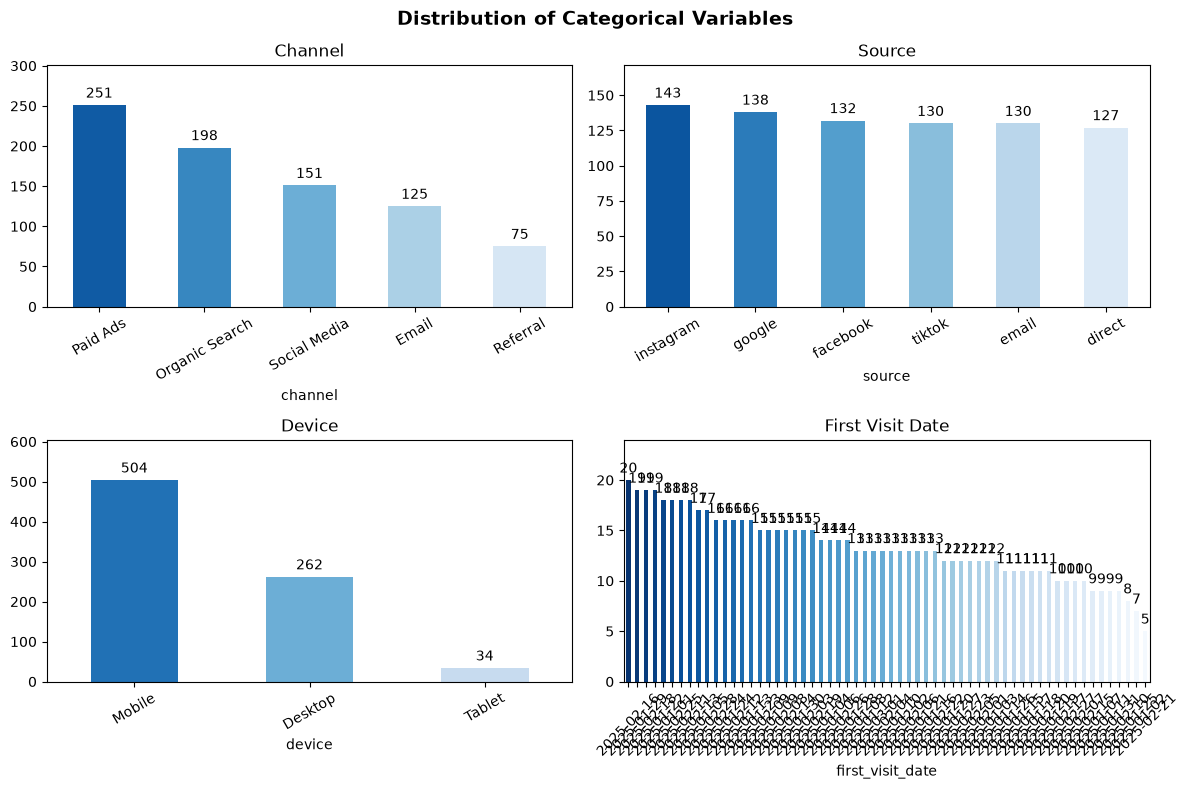

In [18]:
# Membuat layout 2 baris x 2 kolom karena ada 4 kolom kategorikal
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Distribution of Categorical Variables', fontsize=14, fontweight='bold')

# 1. Channel
counts_channel = df['channel'].value_counts()
ax1 = counts_channel.plot(
    kind='bar', 
    ax=axes[0, 0],
    color=sns.color_palette('Blues_r', len(counts_channel))
)
axes[0, 0].bar_label(axes[0, 0].containers[0], padding=3)
axes[0, 0].set_title('Channel')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].set_ylim(0, counts_channel.max() * 1.20)

# 2. Source
counts_source = df['source'].value_counts()
ax2 = counts_source.plot(
    kind='bar', 
    ax=axes[0, 1],
    color=sns.color_palette('Blues_r', len(counts_source))
)
axes[0, 1].bar_label(axes[0, 1].containers[0], padding=3)
axes[0, 1].set_title('Source')
axes[0, 1].tick_params(axis='x', rotation=30)
axes[0, 1].set_ylim(0, counts_source.max() * 1.20)

# 3. Device
counts_device = df['device'].value_counts()
ax3 = counts_device.plot(
    kind='bar', 
    ax=axes[1, 0],
    color=sns.color_palette('Blues_r', len(counts_device))
)
axes[1, 0].bar_label(axes[1, 0].containers[0], padding=3)
axes[1, 0].set_title('Device')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 0].set_ylim(0, counts_device.max() * 1.20)

# 4. First Visit Date (jika kategori tanggalnya tidak terlalu banyak, atau bisa disesuaikan)
counts_date = df['first_visit_date'].value_counts()
ax4 = counts_date.plot(
    kind='bar', 
    ax=axes[1, 1],
    color=sns.color_palette('Blues_r', len(counts_date))
)
axes[1, 1].bar_label(axes[1, 1].containers[0], padding=3)
axes[1, 1].set_title('First Visit Date')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].set_ylim(0, counts_date.max() * 1.20)

plt.tight_layout()
plt.show()

# Memeriksa Data Kosong

In [19]:
pd.isnull(df).sum()

user_id             0
first_visit_date    0
channel             0
source              0
device              0
sessions            0
page_views          0
bounce              0
add_to_cart         0
purchase            0
revenue             0
ad_cost             0
clicks              0
impressions         0
repeat_purchase     0
retention_month     0
dtype: int64

Tidak terdapat missing values pada kolom mana pun

# Memeriksa Data Duplikasi

In [20]:
df.duplicated().sum()

np.int64(0)

Tidak terdapat data duplikasi

## Memeriksa konsistensi data

In [21]:
# Mengatur agar isi kolom (terutama list unique values) tidak terpotong saat ditampilkan
pd.set_option('display.max_colwidth', None)

# Membuat list kosong untuk menampung informasi setiap kolom
list_info = []

# Melakukan iterasi pada setiap kolom di dataframe
for col in df.columns:
    list_info.append([
        col,                                # Nama kolom
        df[col].dtype,                 # Tipe data kolom
        df[col].nunique(),             # Jumlah nilai unik pada kolom
        list(df[col].unique())         # Daftar seluruh nilai unik pada kolom
    ])

# Mengubah list menjadi DataFrame agar lebih mudah dibaca
df_info = pd.DataFrame(
    columns=['column', 'dtype', 'n_unique', 'unique_values'],
    data=list_info
)

# Menampilkan ringkasan informasi kolom
display(df_info)

,column,dtype,n_unique,unique_values
0,user_id,int64,800,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, ...]"
1,first_visit_date,str,60,"[2025-02-17, 2025-01-05, 2025-01-26, 2025-02-24, 2025-01-04, 2025-01-20, 2025-01-24, 2025-02-09, 2025-01-29, 2025-02-27, 2025-01-15, 2025-01-09, 2025-02-16, 2025-02-12, 2025-01-27, 2025-02-08, 2025-02-18, 2025-01-08, 2025-02-14, 2025-01-01, 2025-01-12, 2025-02-25, 2025-02-28, 2025-01-07, 2025-01-06, 2025-02-26, 2025-01-25, 2025-02-23, 2025-03-01, 2025-02-04, 2025-01-10, 2025-02-05, 2025-01-02, 2025-01-17, 2025-02-01, 2025-01-30, 2025-01-11, 2025-02-11, 2025-02-02, 2025-01-22, 2025-02-06, 2025-02-03, 2025-01-28, 2025-01-31, 2025-02-07, 2025-01-18, 2025-01-03, 2025-02-20, 2025-01-19, 2025-01-13, 2025-02-13, 2025-01-21, 2025-01-16, 2025-01-14, 2025-02-22, 2025-01-23, 2025-02-10, 2025-02-19, 2025-02-21, 2025-02-15]"
2,channel,str,5,"[Referral, Paid Ads, Organic Search, Social Media, Email]"
3,source,str,6,"[instagram, facebook, tiktok, direct, google, email]"
4,device,str,3,"[Mobile, Desktop, Tablet]"
5,sessions,int64,7,"[7, 3, 4, 1, 6, 2, 5]"
6,page_views,int64,19,"[4, 5, 2, 18, 7, 10, 17, 14, 12, 1, 16, 15, 9, 13, 11, 3, 8, 6, 19]"
7,bounce,int64,2,"[0, 1]"
8,add_to_cart,int64,2,"[1, 0]"
9,purchase,int64,2,"[1, 0]"


Memperbaiki inkonsistensi tersebut dengan cara mengubah kategorikal menggunakan huruf kapital diawal agar data lebih konsisten

Membuat data frame baru salinan dari df agar ketika digunakan untuk analisis tidak merusak data asli

In [24]:
df_cleaned = df.copy()

## Memperbaiki kategorikal pada kolom source

In [25]:
df_cleaned['source'] = df_cleaned['source'].str.title()

## Mengganti Tipe Data

In [35]:
df_cleaned['first_visit_date'] = pd.to_datetime(df_cleaned['first_visit_date'])

# Deteksi outlier menggunakan IQR

In [37]:
# Pilih semua kolom dengan tipe data integer
int_cols = df_cleaned.select_dtypes(include=['int64', 'int32', 'float64']).columns

# Hitung Q1, Q3, dan IQR
q1 = df_cleaned[int_cols].quantile(0.25)
q3 = df_cleaned[int_cols].quantile(0.75)
iqr = q3 - q1

# Hitung batas bawah dan batas atas
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Buat mask untuk mendeteksi outlier
mask = (df_cleaned[int_cols] < lower) | (df_cleaned[int_cols] > upper)

# Ambil baris yang memiliki minimal satu outlier
outliers = df_cleaned[mask.any(axis=1)]

# Tampilkan kolom integer yang mengandung outlier
outliers[int_cols]

,user_id,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,7,4,0,1,1,401318,0,40,880,0,2
5,6,3,7,0,1,1,437658,12543,35,490,0,2
6,7,4,10,0,1,1,212722,0,6,84,0,4
7,8,3,17,0,1,1,263562,0,44,572,0,2
11,12,6,12,0,1,1,194970,0,31,527,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
772,773,5,17,0,1,0,0,59366,7,203,0,0
774,775,7,1,1,1,1,436406,0,30,600,0,2
785,786,5,4,0,1,1,106441,0,19,247,0,1
790,791,6,7,0,1,1,208552,0,3,48,1,1


# Visualisasi Outlier

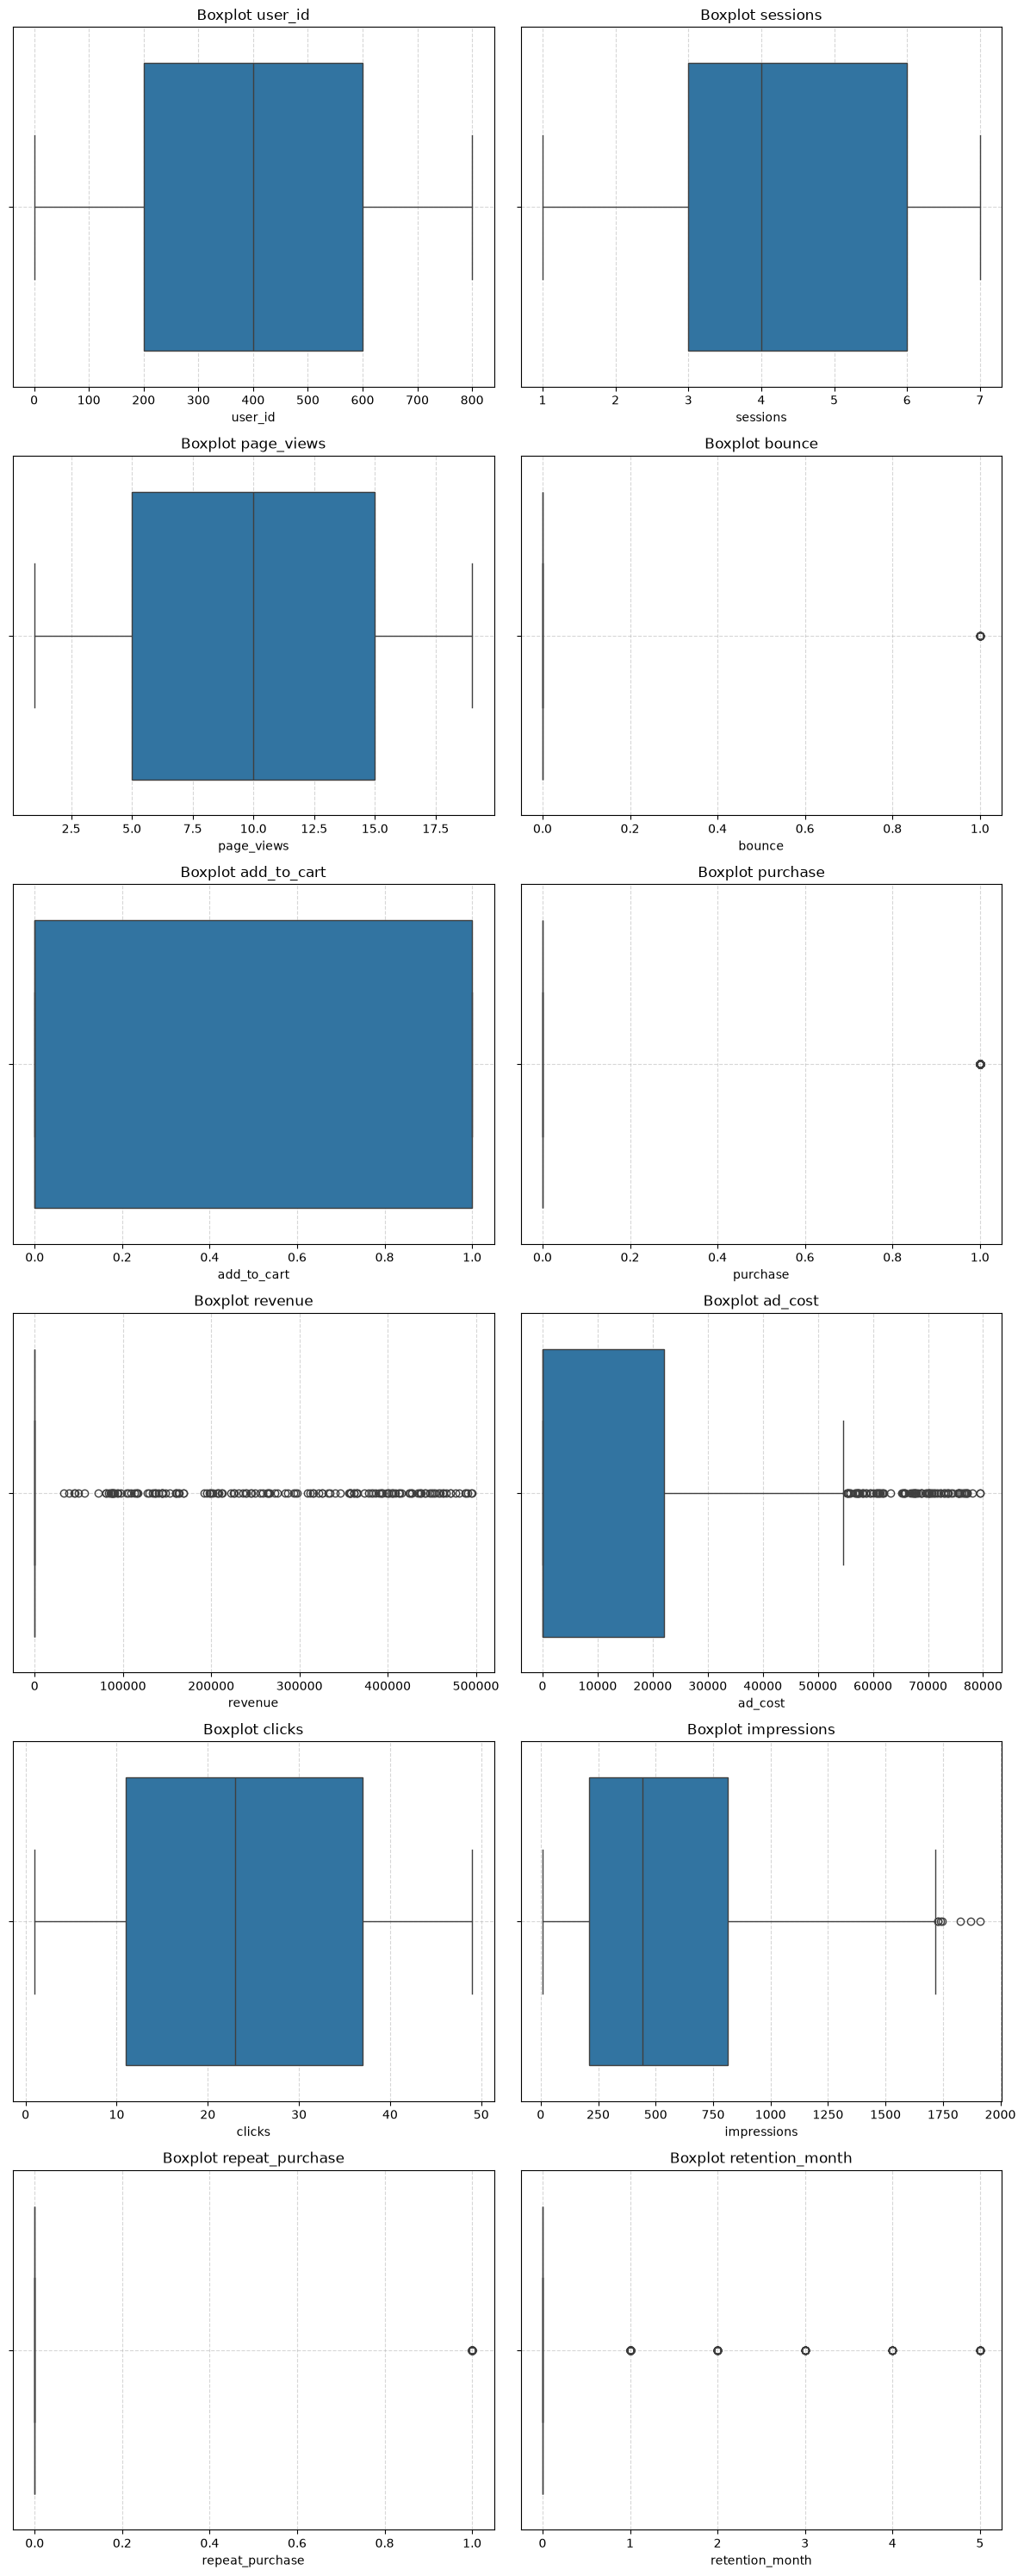

In [36]:
import math

# Ambil semua kolom integer
int_cols = df_cleaned.select_dtypes(include=['int64', 'int32', 'float64']).columns

# Tentukan jumlah kolom
n_cols = len(int_cols)

# Tentukan jumlah baris (2 plot per baris)
n_rows = math.ceil(n_cols / 2)

# Buat subplot
fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5*n_rows))

# Ubah axes jadi 1D array supaya mudah di-loop
axes = axes.flatten()

# Loop untuk membuat boxplot tiap kolom
for i, col in enumerate(int_cols):
    sns.boxplot(x=df_cleaned[col], ax=axes[i])
    axes[i].set_title(f'Boxplot {col}')
    axes[i].grid(True, linestyle='--', alpha=0.5)

# Hapus subplot kosong jika jumlah kolom ganjil
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Outlier dalam dataset ini dipertahankan karena hal tersebut adalah variasi perilaku transaksi dan bukan merupakan kesalahan data. Dengan demikian, analisis tetap merepresentasikan kondisi bisnis yang sebenarnya.

# Encoding

In [31]:
df_raw = df_cleaned.copy()

In [42]:
from sklearn.preprocessing import LabelEncoder
encoding = [   # kolom kategorikal yang akan di encoding
    'channel',	
    'source',	
    'device'
]


label_encoders = {} # Membuat dictionary untuk menyimpan objek LabelEncoder untuk tiap kolom

for col in encoding:
    le = LabelEncoder() # Membuat instance LabelEncoder baru
    df_raw[col] = le.fit_transform(df_raw[col])
    label_encoders[col] = le   # Menyimpan LabelEncoder di dictionary supaya bisa memeriksa mapping label seperti kategori label 1 itu apa


In [43]:
non = [
      'sessions',
      'page_views',
      'bounce',
      'add_to_cart',
      'purchase',
      'revenue',
      'ad_cost',
      'clicks',          
      'impressions',
      'repeat_purchase',
      'retention_month'
]

In [44]:
df_final = df_raw[non + encoding]
df_final.head()

,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month,channel,source,device
0,7,4,0,1,1,401318,0,40,880,0,2,3,4,1
1,3,5,0,0,0,0,0,12,264,0,0,3,2,1
2,4,5,0,0,0,0,0,3,72,0,0,3,5,1
3,4,2,0,1,0,0,18215,16,320,0,0,2,2,1
4,1,18,0,0,0,0,0,44,792,0,0,3,4,1


In [45]:
for col, le in label_encoders.items():
    print(f"\nKolom: {col}") # Menampilkan nama kolom yang sedang dicek
    label_mapping = pd.DataFrame({ # Membuat tabel dataframe untuk melihat mapping antara angka hasil labeling dan kategori asli
        'Label': le.transform(le.classes_), # Mengubah kategori asli ke angka sesuai encoder
        'Kategori_Asli': le.classes_  # Menampilkan kategori asli
    })
    print(label_mapping)



Kolom: channel
   Label  Kategori_Asli
0      0              0
1      1              1
2      2              2
3      3              3
4      4              4

Kolom: source
   Label  Kategori_Asli
0      0              0
1      1              1
2      2              2
3      3              3
4      4              4
5      5              5

Kolom: device
   Label  Kategori_Asli
0      0              0
1      1              1
2      2              2


# Heatmap

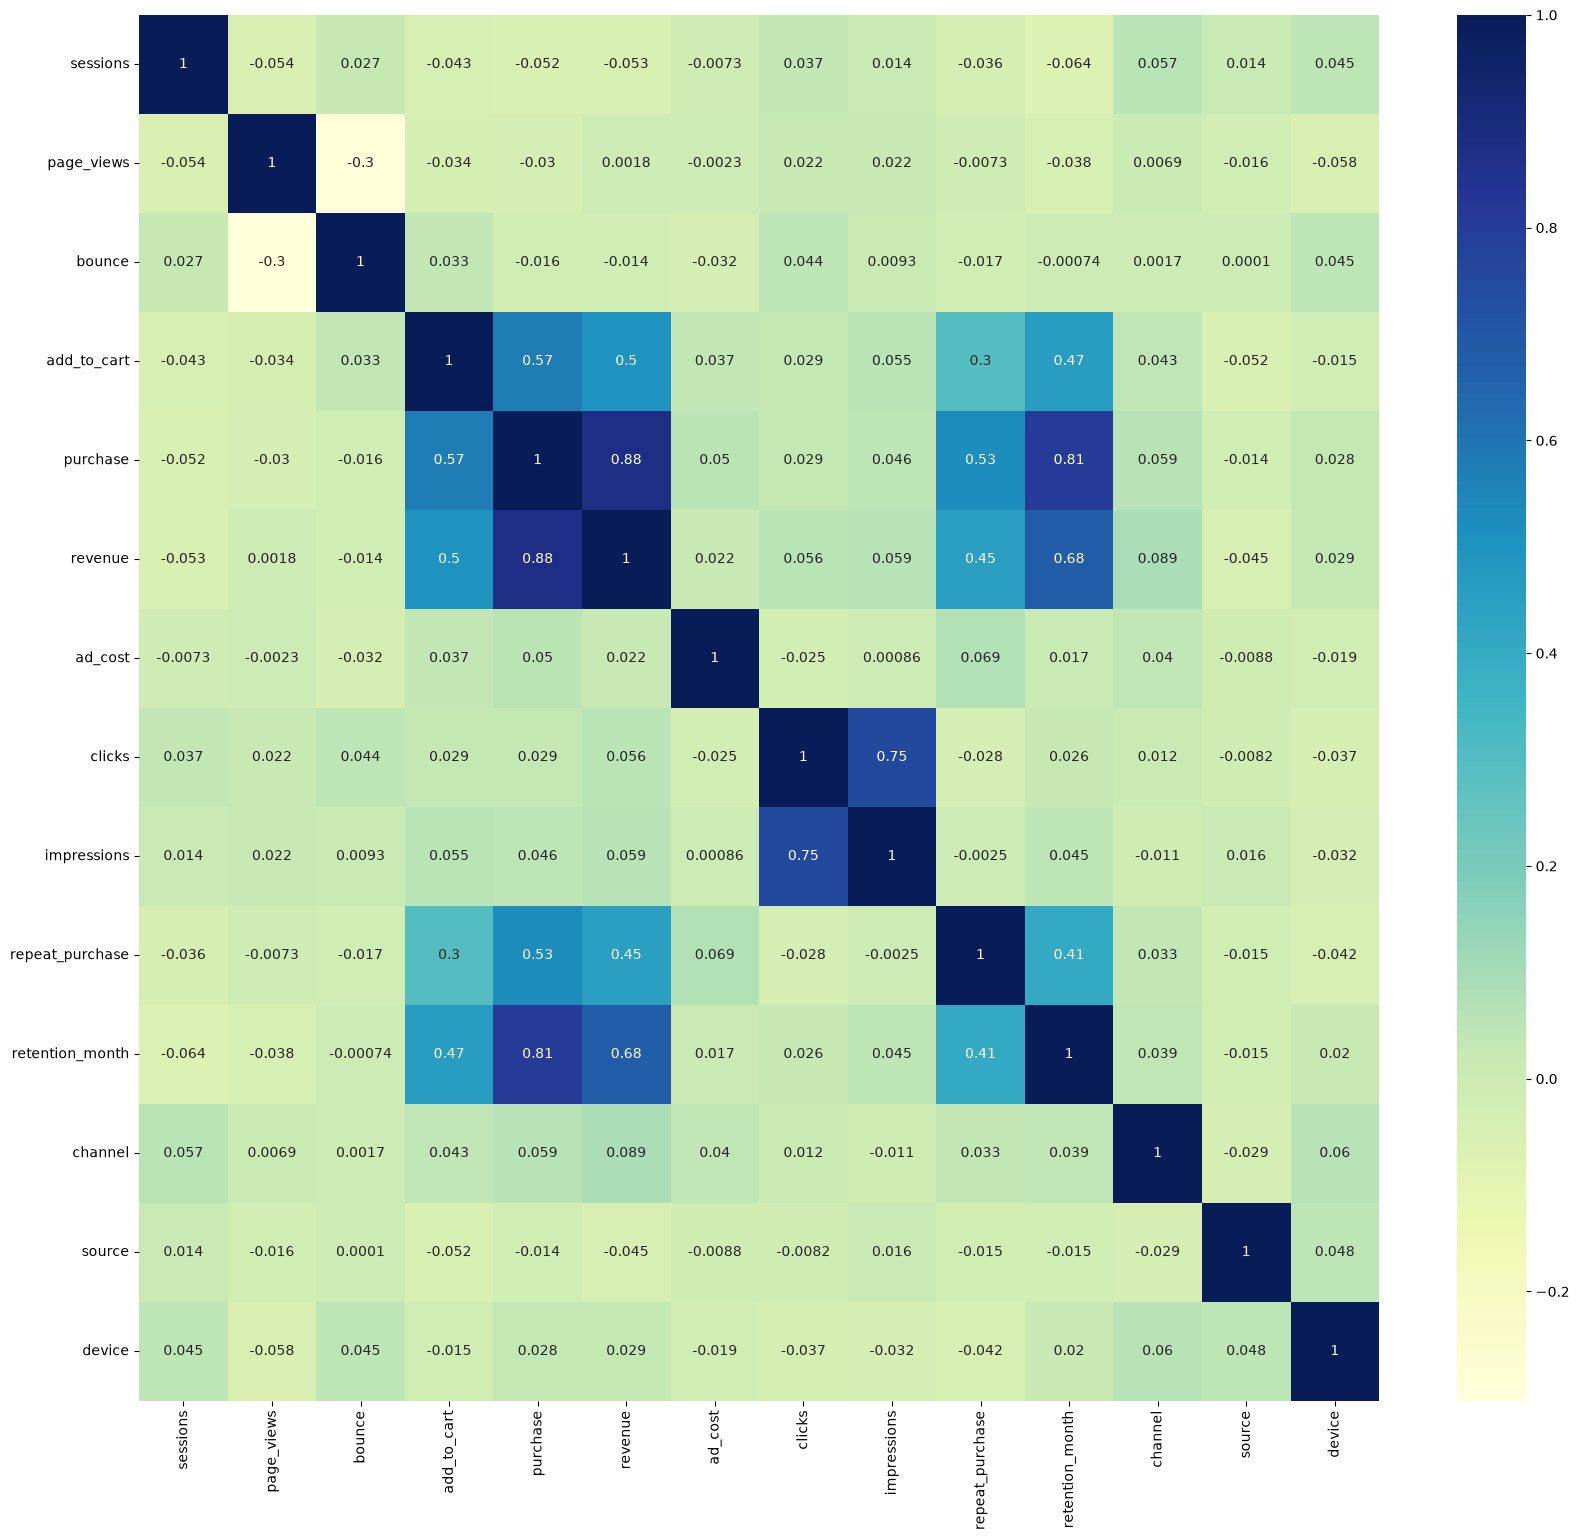

In [46]:
plt.figure(figsize=(20, 18))

# Hitung matriks korelasi
co_mtx = df_final.corr(numeric_only=True)

# Plot correlation heatmap
sns.heatmap(co_mtx, cmap="YlGnBu", annot=True)

# Menampilkan heatmap
plt.show()